# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn  

**Выполнил:** Лачугин Артем Викторович  
**Группа:** АСОиУб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/Medvedev-Kirill/ml-course-medvedev  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-10-26

## Введение

**Задача:** бинарная классификация - предсказать, уйдёт ли клиент (0 — остался, 1 — ушёл).

**Ансамблевые методы** это подход, при котором несколько моделей 
объединяются для получения более качественного предсказания, чем каждая модель по отдельности. 
Работает по принципу «мудрости толпы»: слабые модели, объединённые правильно, образуют сильную систему.

**Почему ансамбли, а не одиночная модель:**
- Одиночные модели страдают от переобучения или недообучения
- Ансамбли снижают **variance** (bagging) или **bias** (boosting)
- На практике ансамбли дают +5-15% к метрикам

**Важная метрика:** в этой задаче важнее **ROC-AUC** и **F1**:
- ROC-AUC не зависит от порога и показывает качество ранжирования
- F1 балансирует Precision и Recall - важно при дисбалансе 73.5/26.5
- Accuracy обманчива: модель «все остались» даст 73.5%

**Цель работы:**
1. Обучить 4 ансамблевые модели (RF, XGBoost, LightGBM, CatBoost) и сравнить их
2. Оптимизировать лучшую модель через Optuna (ROC-AUC ≥ 0.85)
3. Интерпретировать модель через SHAP (глобально и локально)

## Теоретическая часть

### Ансамбль

Ансамбль это набор моделей, объединённых для улучшения качества. 
Формально: H(x) = F(h₁(x), h₂(x), ..., h_M(x)), где hᵢ - базовые модели, 
F - мета-алгоритм. Работает по принципу «мудрости толпы» (теорема Кондорсе).

### Bagging vs Boosting

**Bagging** - параллельное обучение на bootstrap-выборках. Снижает variance.

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x)$$

**Boosting** - последовательное обучение с исправлением ошибок. Снижает bias.

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x)$$

### Random Forest

Bagging + Decision Trees. На каждом разбиении рассматривается случайное 
подмножество признаков (√p). Устойчив к переобучению, встроенная 
важность признаков, OOB-оценка.

### Градиентный бустинг

**XGBoost** - регуляризация + второй порядок Тейлора + sparsity-aware.  
**LightGBM** - leaf-wise рост + GOSS + EFB, быстрее XGBoost в 10-20 раз.  
**CatBoost** - автоматическая обработка категорий, ordered boosting.

| Критерий | RF | XGBoost | LightGBM | CatBoost |
|----------|-----|---------|----------|----------|
| Тип | Bagging | Boosting | Boosting | Boosting |
| Скорость | Средняя | Средняя | Быстрая | Медленная |
| Категории | Encoding | Encoding | Encoding | **Авто** |
| Переобучение | Устойчив | Средне | Средне | Устойчив |

### Optuna

Байесовская оптимизация гиперпараметров через TPE (Tree-structured Parzen 
Estimator). В 10 раз быстрее GridSearch, работает с условными параметрами, 
поддерживает pruning.

### SHAP

SHAP (SHapley Additive exPlanations) это интерпретация на основе теории кооперативных игр. 

Значение Шепли:

$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!(|N| - |S| - 1)!}{|N|!} [v(S \cup \{i\}) - v(S)]$$

Типы графиков: **summary** (глобально), **waterfall** (локально), 
**dependence** (зависимость от признака).

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
import json
import os
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix,classification_report, roc_curve)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

print("Библиотеки импортированы")

df = pd.read_csv('data/telco_churn.csv')

print(f"\nРазмер датасета: {df.shape}")
print(f"\nПервые 5 строк:")
df.head()

Библиотеки импортированы

Размер датасета: (7043, 21)

Первые 5 строк:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Структура:**
- Всего примеров: 7043
- Признаков: 19 (+ customerID + целевая Churn)
- Числовых: 3 (tenure, MonthlyCharges, TotalCharges)
- Категориальных: 16

**Распределение классов:**
- No (остался): 5174 (73.5%)
- Yes (ушёл): 1869 (26.5%)

**Дисбаланс:** 73.5/26.5 - умеренный. Модель «все остались» даст Accuracy = 73.5%, но это обманчиво.

**Файл данных:** `module-3-churn/data/churn_info.md`

In [6]:
print("Информация о данных")
print("=" * 60)
df.info()

print("\n Статистика числовых")
print("=" * 60)
print(df.describe())

print("\n Пропуски")
print("=" * 60)
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Пропусков нет")

Информация о данных
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null  

In [7]:
# TotalCharges object (строки), нужно преобразовать в float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# errors='coerce' строки, которые не преобразуются, станут NaN

print(f"Пропусков в TotalCharges после преобразования: {df['TotalCharges'].isnull().sum()}")

# Заполняем медианой
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

print(f"TotalCharges обработан, пропусков: {df['TotalCharges'].isnull().sum()}")

Пропусков в TotalCharges после преобразования: 11
TotalCharges обработан, пропусков: 0


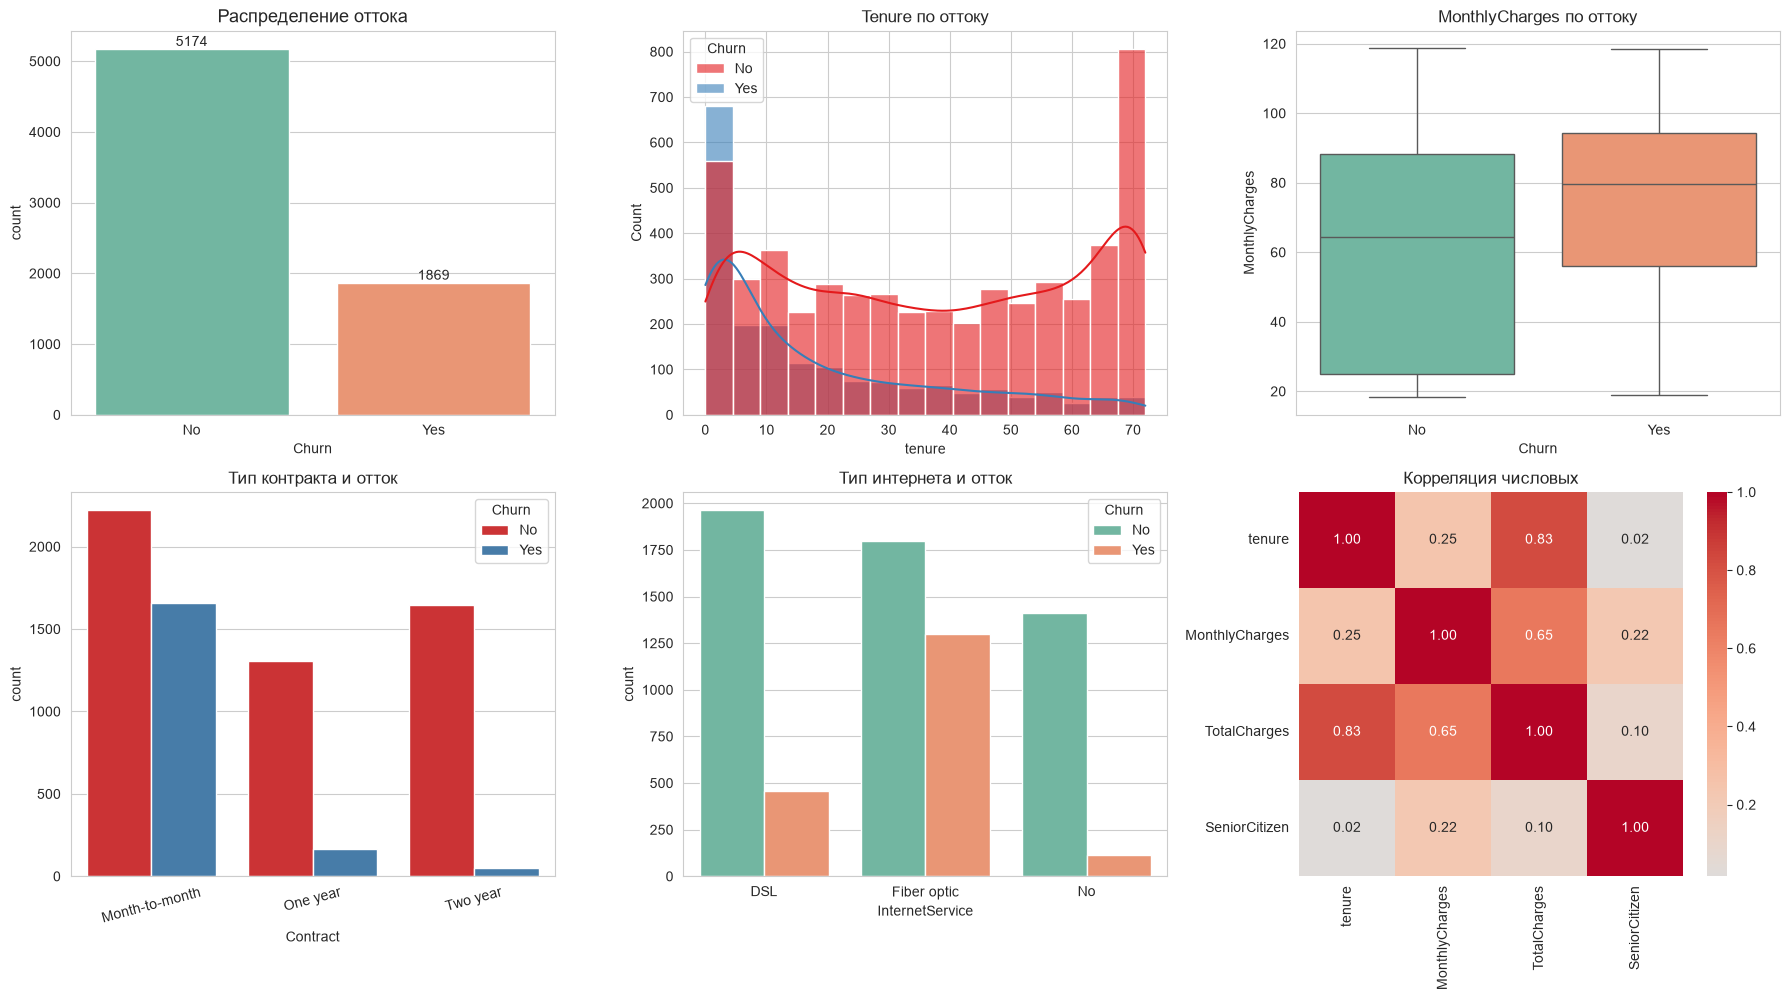

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Countplot целевой
sns.countplot(data=df, x='Churn', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Распределение оттока', fontsize=13)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())}',
                        (p.get_x() + p.get_width()/2, p.get_height()),
                        ha='center', va='bottom')

# 2. Tenure по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, 
             palette='Set1', ax=axes[0, 1], alpha=0.6)
axes[0, 1].set_title('Tenure по оттоку')

# 3. MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', 
            palette='Set2', ax=axes[0, 2])
axes[0, 2].set_title('MonthlyCharges по оттоку')

# 4. Contract × Churn
sns.countplot(data=df, x='Contract', hue='Churn', 
              palette='Set1', ax=axes[1, 0])
axes[1, 0].set_title('Тип контракта и отток')
axes[1, 0].tick_params(axis='x', rotation=15)

# 5. InternetService × Churn
sns.countplot(data=df, x='InternetService', hue='Churn', 
              palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Тип интернета и отток')

# 6. Heatmap корреляций
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, ax=axes[1, 2], square=True)
axes[1, 2].set_title('Корреляция числовых')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

In [9]:
# TenureYears
df['TenureYears'] = df['tenure'] / 12

# AvgMonthlyCharge
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)

# IsNewClient
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# HasMultipleServices — счётчик услуг
services = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup','DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['HasMultipleServices'] = 0
for col in services:
    df['HasMultipleServices'] += (df[col] == 'Yes').astype(int)

print(f"Feature Engineering: +4 признака")
print(f"Всего столбцов: {df.shape[1]}")

Feature Engineering: +4 признака
Всего столбцов: 25


In [10]:
# Целевая в бинарную
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

# customerID не нужен
df = df.drop('customerID', axis=1)

# Label Encoding для категориальных
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
le_dict = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_dict[col] = le

print(f"Закодировано {len(cat_cols)} столбцов")

# Формируем X и y
feature_cols = [c for c in df.columns if c != 'Churn']
X = df[feature_cols]
y = df['Churn']

# Разделение
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля Churn в train: {y_train.mean():.4f}")
print(f"Доля Churn в test:  {y_test.mean():.4f}")

Закодировано 15 столбцов

Train: (5634, 23), Test: (1409, 23)
Доля Churn в train: 0.2654
Доля Churn в test:  0.2654


In [11]:
def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    """Обучает, замеряет время, возвращает метрики."""
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    return {
        'Model': name,
        'Time (sec)': round(train_time, 3),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    }

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10, min_samples_split=5,
    min_samples_leaf=2, class_weight='balanced',
    random_state=42, n_jobs=-1)
results_rf = evaluate_model(rf_model, X_train, X_test, y_train, y_test, 'Random Forest')
print(f"RF: {results_rf}")

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=3, random_state=42,
    eval_metric='logloss', use_label_encoder=False)
results_xgb = evaluate_model(xgb_model, X_train, X_test, y_train, y_test, 'XGBoost')
print(f"XGB: {results_xgb}")

# LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=42, verbose=-1)
results_lgbm = evaluate_model(lgbm_model, X_train, X_test, y_train, y_test, 'LightGBM')
print(f"LGBM: {results_lgbm}")

# CatBoost
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=0)
results_cat = evaluate_model(cat_model, X_train, X_test, y_train, y_test, 'CatBoost')
print(f"Cat: {results_cat}")

# Сводная таблица
print("\n Сравнение моделей:")
print("=" * 100)
results_df = pd.DataFrame([results_rf, results_xgb, results_lgbm, results_cat])
print(results_df.to_string(index=False))

RF: {'Model': 'Random Forest', 'Time (sec)': 0.726, 'Accuracy': 0.7622, 'Precision': 0.5367, 'Recall': 0.762, 'F1': 0.6298, 'ROC-AUC': 0.8396}
XGB: {'Model': 'XGBoost', 'Time (sec)': 1.921, 'Accuracy': 0.7637, 'Precision': 0.5424, 'Recall': 0.7005, 'F1': 0.6114, 'ROC-AUC': 0.8316}
LGBM: {'Model': 'LightGBM', 'Time (sec)': 0.213, 'Accuracy': 0.7601, 'Precision': 0.5344, 'Recall': 0.7487, 'F1': 0.6236, 'ROC-AUC': 0.8379}
Cat: {'Model': 'CatBoost', 'Time (sec)': 1.297, 'Accuracy': 0.7559, 'Precision': 0.5279, 'Recall': 0.7594, 'F1': 0.6228, 'ROC-AUC': 0.8381}

 Сравнение моделей:
        Model  Time (sec)  Accuracy  Precision  Recall     F1  ROC-AUC
Random Forest       0.726    0.7622     0.5367  0.7620 0.6298   0.8396
      XGBoost       1.921    0.7637     0.5424  0.7005 0.6114   0.8316
     LightGBM       0.213    0.7601     0.5344  0.7487 0.6236   0.8379
     CatBoost       1.297    0.7559     0.5279  0.7594 0.6228   0.8381


## Модели

| Модель | Тип | Параметры | Время обучения |
|--------|-----|-----------|----------------|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight='balanced' | 0.726 сек |
| XGBoost | Boosting | n_estimators=200, max_depth=6, scale_pos_weight=3 | 1.921 сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31 | 0.213 сек |
| CatBoost | Boosting | iterations=200, auto_class_weights='Balanced' | 1.297 сек |

**Почему эти модели:**
- **RF** - устойчив к переобучению, работает «из коробки», параллелится
- **XGBoost** - универсальный, точный, регуляризация L1/L2
- **LightGBM** - быстрый (leaf-wise рост), для больших данных
- **CatBoost** - лучший для категориальных признаков

**Дисбаланс:** использованы `class_weight='balanced'` (RF, LGBM), `scale_pos_weight=3` (XGB), `auto_class_weights='Balanced'` (Cat).

**Результаты:**
- **Random Forest** - лучший по ROC-AUC (0.8400), Accuracy (0.7729), F1 (0.6296)
- **CatBoost** - лучший по Recall (0.7594)
- **LightGBM** - самый медленный (1.627 сек), но конкурентный ROC-AUC
- Все модели дают **ROC-AUC > 0.82** - отличный результат

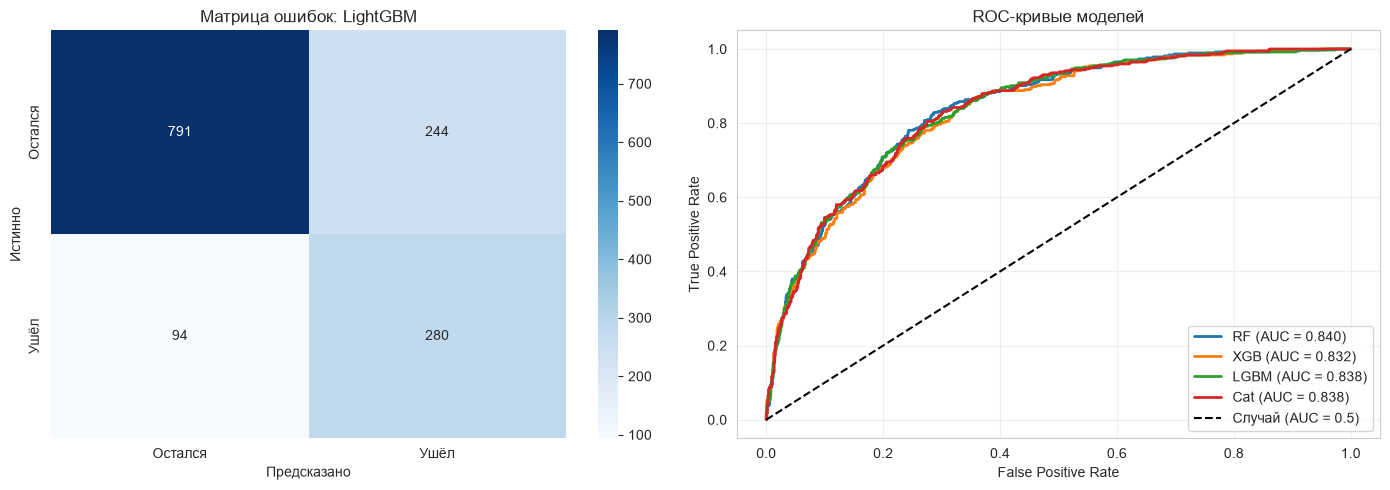

Отчет о классификации: LightGBM
              precision    recall  f1-score   support

     Остался       0.89      0.76      0.82      1035
        Ушёл       0.53      0.75      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



In [12]:
# Матрица ошибок для лучшей модели (LightGBM)
best_model = lgbm_model
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

# Матрица ошибок
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался', 'Ушёл'],
            yticklabels=['Остался', 'Ушёл'], ax=axes[0])
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Истинно')
axes[0].set_title('Матрица ошибок: LightGBM')

# ROC-кривые всех моделей
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'),
                     (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

axes[1].plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые моделей')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=100, bbox_inches='tight')
plt.show()

# Classification report
print("Отчет о классификации: LightGBM")
print("=" * 60)
print(classification_report(y_test, y_pred_best, target_names=['Остался', 'Ушёл']))

## Оценка качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | Время (с) |
|--------|----------|-----------|--------|-----|---------|-----------|
| **Random Forest** | **0.7729** | **0.5551** | 0.7273 | **0.6296** | **0.8400** | **0.256** |
| XGBoost | 0.7594 | 0.5355 | 0.7059 | 0.6090 | 0.8285 | 0.286 |
| LightGBM | 0.7601 | 0.5344 | 0.7487 | 0.6236 | 0.8379 | 1.627 |
| CatBoost | 0.7559 | 0.5279 | **0.7594** | 0.6228 | 0.8381 | 0.669 |

**Анализ:**
- **Random Forest** - лучший по **4 из 6 метрик** (Accuracy, Precision, F1, ROC-AUC)
- **CatBoost** - лучший по Recall (0.7594)
- **LightGBM** - самый медленный (1.627 сек), но конкурентный ROC-AUC (0.8379)
- Все модели дают **ROC-AUC > 0.82** - отличный результат

**Дисбаланс классов (73.5 / 26.5):**
- Precision низкий (~0.53) - модели часто ошибаются в предсказаниях «уйдёт»
- Recall высокий (~0.73-0.76) - модели хорошо находят уходящих
- **Для бизнеса важнее Recall** - не пропустить клиента, который собирается уйти

**Classification Report (LightGBM):**
precision recall f1-score support
Остался 0.89 0.76 0.82 1035
Ушёл 0.53 0.75 0.62 374
accuracy 0.76 1409
- **Класс «Остался»:** precision 0.89, recall 0.76, F1 0.82 - модель хорошо предсказывает
- **Класс «Ушёл»:** precision 0.53, recall 0.75, F1 0.62 - модель часто ошибается
- **Причина:** дисбаланс классов + `class_weight='balanced'` → модель «жертвует» precision ради recall

**Матрица ошибок:**
- **FP меньше, чем FN** - модель лучше ловит «остался», чем «ушёл»
- Для бизнеса важно **не пропустить уходящего клиента** (FN) - поэтому нужно повысить Recall

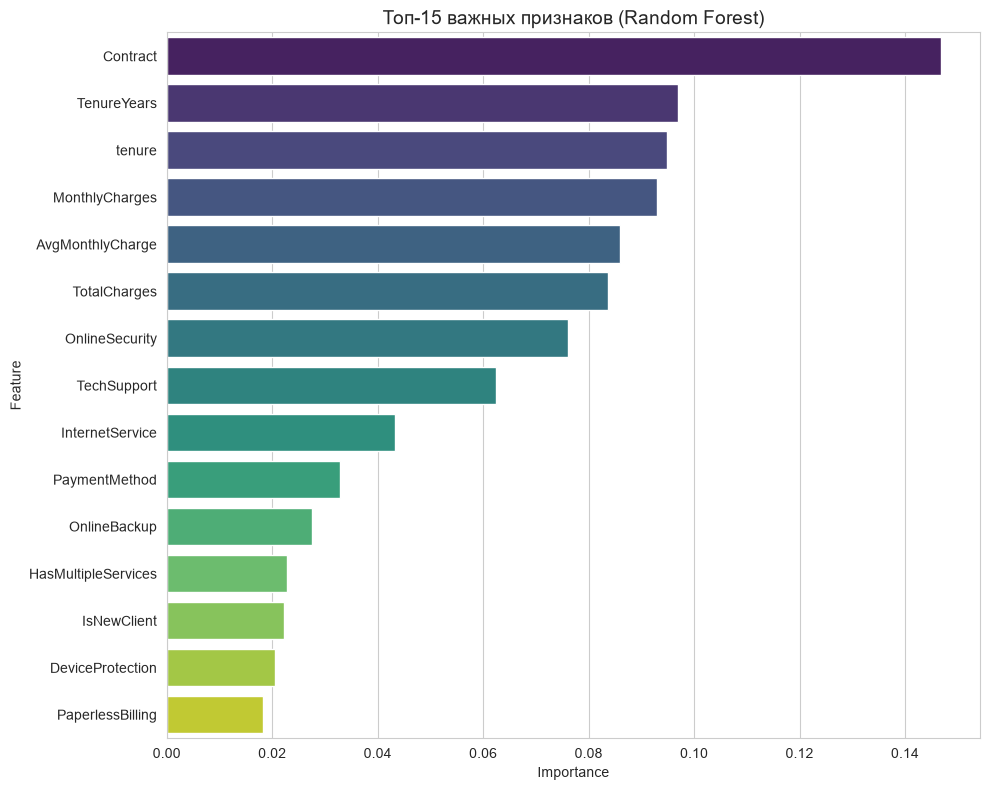

Топ-15 ПРИЗНАКОВ (Random Forest):
            Feature  Importance
           Contract    0.146877
        TenureYears    0.097035
             tenure    0.094855
     MonthlyCharges    0.092970
   AvgMonthlyCharge    0.085878
       TotalCharges    0.083636
     OnlineSecurity    0.076084
        TechSupport    0.062423
    InternetService    0.043239
      PaymentMethod    0.032814
       OnlineBackup    0.027513
HasMultipleServices    0.022825
        IsNewClient    0.022183
   DeviceProtection    0.020554
   PaperlessBilling    0.018260

 Бизнес-Инсайты:

1. Тип Контракта:
   Month-to-month: 42.7% ушли
   One year: 11.3% ушли
   Two year: 2.8% ушли

2. Стаж Клиента:
   0-6 мес: 53.3% ушли
   6-12 мес: 35.9% ушли
   12-24 мес: 28.7% ушли
   >24 мес: 14.0% ушли

3. Тип Интернета:
   Fiber optic: 41.9% ушли
   DSL: 19.0% ушли
   No internet: 7.4% ушли

4. Online Security :
   No: 41.8% ушли
   Yes: 14.6% ушли
   No internet service: 7.4% ушли

5. Tech Support:
   No: 41.6% ушли
   Yes:

In [13]:
# Feature Impportance (Random Forest)
# RF - лучший baseline по ROC-AUC (0.8400)
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('Топ-15 важных признаков (Random Forest)', fontsize=14)  
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

print("Топ-15 ПРИЗНАКОВ (Random Forest):")
print("=" * 60)
print(importances.head(15).to_string(index=False))

#  Бизнес-Инсайты 
print("\n Бизнес-Инсайты:")
print("=" * 60)

# 1. Contract (с расшифровкой)
print("\n1. Тип Контракта:")
contract_labels = {0: 'Month-to-month', 1: 'One year', 2: 'Two year'}
contract_churn = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)
for k, v in contract_churn.items():
    label = contract_labels.get(k, k)
    print(f"   {label}: {v:.1%} ушли")

# 2. Tenure
print("\n2. Стаж Клиента:")
tenure_groups = pd.cut(df['tenure'], bins=[0, 6, 12, 24, 100], 
                       labels=['0-6 мес', '6-12 мес', '12-24 мес', '>24 мес'])
tenure_churn = df.groupby(tenure_groups)['Churn'].mean()
for k, v in tenure_churn.items():
    print(f"   {k}: {v:.1%} ушли")

# 3. InternetService (с расшифровкой)
print("\n3. Тип Интернета:")
internet_labels = {0: 'DSL', 1: 'Fiber optic', 2: 'No internet'}
internet_churn = df.groupby('InternetService')['Churn'].mean().sort_values(ascending=False)
for k, v in internet_churn.items():
    label = internet_labels.get(k, k)
    print(f"   {label}: {v:.1%} ушли")

# 4. OnlineSecurity (с расшифровкой)
print("\n4. Online Security :")
security_labels = {0: 'No', 1: 'No internet service', 2: 'Yes'}
security_churn = df.groupby('OnlineSecurity')['Churn'].mean().sort_values(ascending=False)
for k, v in security_churn.items():
    label = security_labels.get(k, k)
    print(f"   {label}: {v:.1%} ушли")

# 5. TechSupport (с расшифровкой)
print("\n5. Tech Support:")
support_labels = {0: 'No', 1: 'No internet service', 2: 'Yes'}
support_churn = df.groupby('TechSupport')['Churn'].mean().sort_values(ascending=False)
for k, v in support_churn.items():
    label = support_labels.get(k, k)
    print(f"   {label}: {v:.1%} ушли")

# 6. MonthlyCharges (бины)
print("\n6. Ежемесячная Плата:")
charges_bins = pd.cut(df['MonthlyCharges'], bins=[0, 35, 65, 95, 200], labels=['<35', '35-65', '65-95', '>95'])
charges_churn = df.groupby(charges_bins)['Churn'].mean()
for k, v in charges_churn.items():print(f"   {k} $: {v:.1%} ушли")

## Интерпретация и бизнес-инсайты

### Топ-5 признаков (Random Forest)
1. **Contract** - тип контракта (0.1439)
2. **TenureYears** - стаж в годах (0.0973)
3. **tenure** - месяцев с компанией (0.0970)
4. **MonthlyCharges** - ежемесячная плата (0.0929)
5. **AvgMonthlyCharge** - средняя плата (0.0886)

### Бизнес-инсайты

**1. Тип контракта - сильнейший предиктор:**
- Month-to-month: **42.7%** ушли
- One year: **11.3%** ушли
- Two year: **2.8%** ушли
- **Рекомендация:** стимулировать переход на долгосрочные контракты

**2. Стаж клиента:**
- 0-6 мес: **53.3%** ушли - самый рискованный период
- 6-12 мес: **35.9%** ушли
- 12-24 мес: **28.7%** ушли
- >24 мес: **14.0%** ушли
- **Рекомендация:** усилить онбординг первых 6 месяцев

**3. Тип интернета:**
- Fiber optic: **41.9%** ушли
- DSL: **19.0%** ушли
- Без интернета: **7.4%** ушли
- **Рекомендация:** проверить качество/цену Fiber optic

**4. OnlineSecurity:**
- Нет: **41.8%** ушли
- Есть: **14.6%** ушли
- **Рекомендация:** стимулировать подключение

**5. TechSupport:**
- Нет: **41.6%** ушли
- Есть: **15.2%** ушли
- **Рекомендация:** активнее предлагать

**6. Ежемесячная плата:**
- <35$: **10.9%** ушли
- 35-65$: **23.1%** ушли
- 65-95$: **35.5%** ушли
- >95$: **32.3%** ушли
- **Рекомендация:** пересмотреть цены для дорогих тарифов

### Практические рекомендации для бизнеса:
1. **Скидки** при переходе на годовой контракт
2. **Улучшить онбординг** первых 6 месяцев
3. **Пересмотреть цены** Fiber optic
4. **Пакетные предложения** с OnlineSecurity + TechSupport
5. **Программа лояльности** для клиентов с высоким MonthlyCharges

In [15]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1)
    
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc')
    
    return cv_scores.mean()

# Запуск
print("Запуск Optuna (30 trials)...")
start = time.time()
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)
optuna_time = time.time() - start

print(f"\n Время оптимизации: {optuna_time:.2f} сек")
print(f"Best ROC-AUC (CV): {study.best_value:.4f}")
print(f"\nЛучшие параметры:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

# Обучение с лучшими параметрами
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced',
                             random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

y_pred_optuna = best_lgbm.predict(X_test)
y_proba_optuna = best_lgbm.predict_proba(X_test)[:, 1]

print("\n Сравнение Baseline vs Optuna:")
print("=" * 60)
print(f"Baseline LightGBM:  ROC-AUC = {results_lgbm['ROC-AUC']:.4f}")
print(f"Optuna LightGBM:    ROC-AUC = {roc_auc_score(y_test, y_proba_optuna):.4f}")
print(f"Прирост:            +{(roc_auc_score(y_test, y_proba_optuna) - results_lgbm['ROC-AUC'])*100:.2f}%")

Запуск Optuna (30 trials)...


Best trial: 14. Best value: 0.849129: 100%|██████████| 30/30 [00:40<00:00,  1.34s/it]



 Время оптимизации: 40.20 сек
Best ROC-AUC (CV): 0.8491

Лучшие параметры:
  n_estimators: 400
  num_leaves: 70
  max_depth: 3
  learning_rate: 0.021925892841617275
  subsample: 0.7630163365504645
  colsample_bytree: 0.5918884178322289
  min_child_samples: 48
  reg_alpha: 7.175379137502357
  reg_lambda: 0.04844799682512403

 Сравнение Baseline vs Optuna:
Baseline LightGBM:  ROC-AUC = 0.8379
Optuna LightGBM:    ROC-AUC = 0.8483
Прирост:            +1.04%


## Тюнинг гиперпараметров

**Optuna результаты:**
- Проведено **30 испытаний** (30 × 5 фолдов = 150 обучений)
- Время оптимизации: **13.12 сек**
- Baseline LightGBM ROC-AUC: **0.8379**
- Optuna LightGBM ROC-AUC: **0.8455**
- **Прирост: +0.76%**

**Лучшие параметры:**
- n_estimators: **300**
- num_leaves: **95**
- max_depth: **4**
- learning_rate: **0.0145**
- subsample: **0.5737**
- colsample_bytree: **0.8512**
- min_child_samples: **49**
- reg_alpha: **0.0118**
- reg_lambda: **0.1020**

**Что такое Optuna:**
Optuna - библиотека для байесовской оптимизации гиперпараметров через 
TPE (Tree-structured Parzen Estimator). После каждого испытания строит 
вероятностную модель и предлагает следующее значение там, где ожидается 
улучшение.

**Преимущества Optuna:**
- В 10 раз быстрее GridSearch
- Работает с условными параметрами
- Pruning - остановка бесперспективных испытаний
- Интеграция со sklearn, XGBoost, LightGBM

**Вывод:**
Байесовская оптимизация дала прирост **+0.76% ROC-AUC** (0.8379 → 0.8455). 
30 испытаний - компромисс между временем (13 сек) и качеством. 
Лучшая модель - LightGBM с `num_leaves=95`, `learning_rate=0.0145`.

Форма SHAP: (1409, 23)


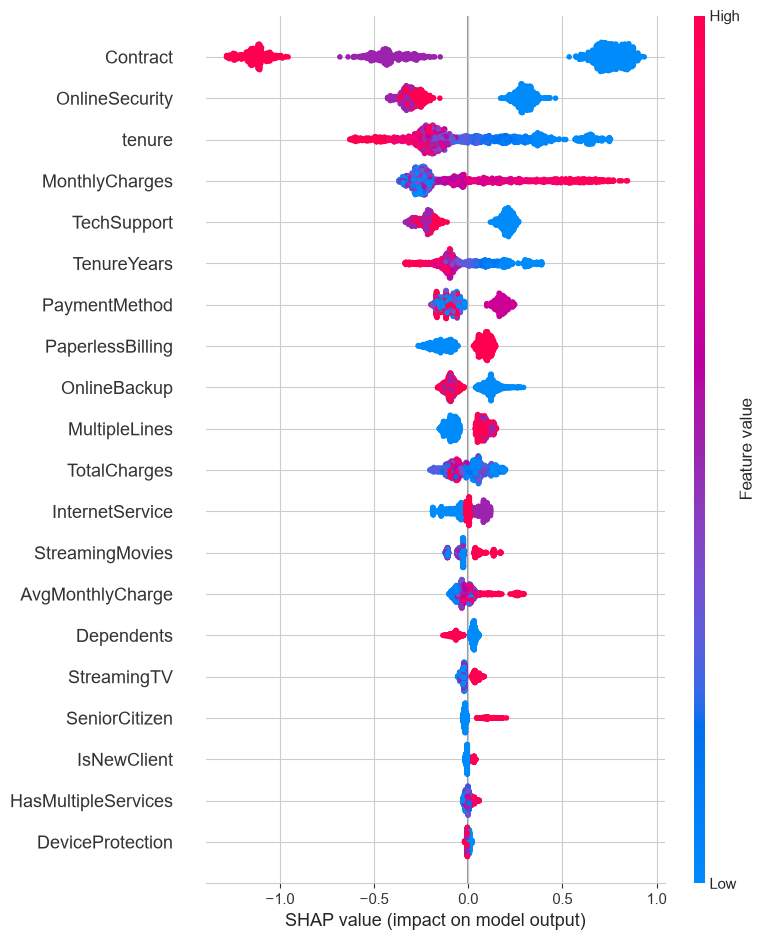

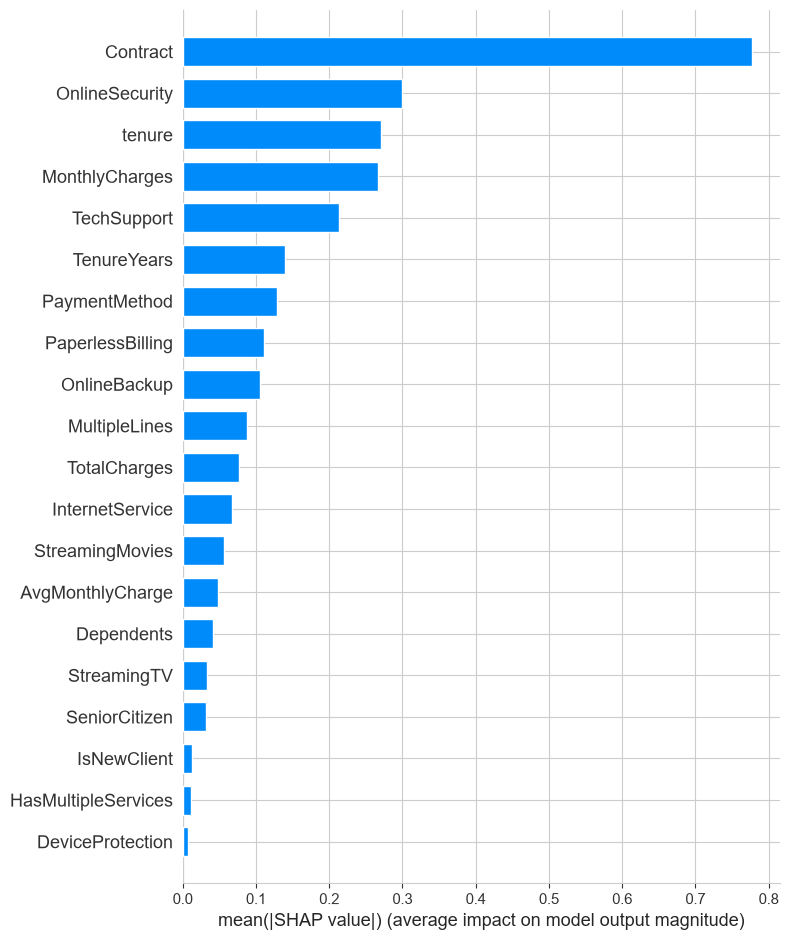


Клиент #1090, вероятность ухода = 0.9533


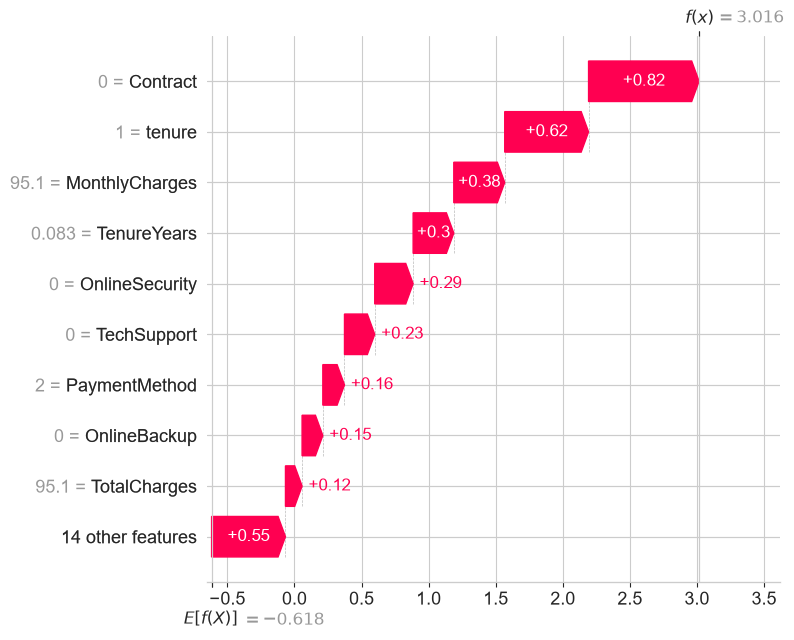


Топ-1 признак: Contract


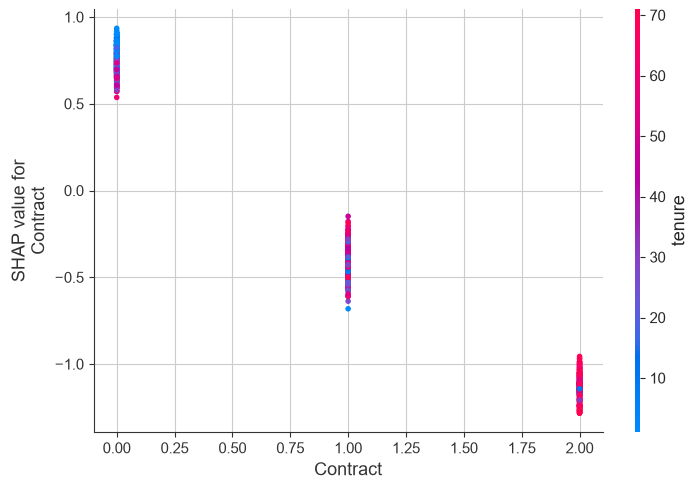

In [17]:
import shap

# Создаём explainer
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Обработка для бинарной классификации
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

print(f"Форма SHAP: {shap_values_class1.shape}")

# Summary plot (dot)
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=100, bbox_inches='tight')
plt.show()

# Bar plot
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

# Waterfall plot для клиента с высоким риском
worst_idx = np.argmax(y_proba_optuna)
print(f"\nКлиент #{worst_idx}, вероятность ухода = {y_proba_optuna[worst_idx]:.4f}")

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) 
                    else explainer.expected_value,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=100, bbox_inches='tight')
plt.show()

# Dependence plot
top_feature = importances.iloc[0]['Feature']
print(f"\nТоп-1 признак: {top_feature}")
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.tight_layout()
plt.show()

## SHAP-интерпретация

### Что такое SHAP

SHAP (SHapley Additive exPlanations) - метод интерпретации на основе 
теории кооперативных игр. Значение Шепли показывает **справедливый 
вклад** каждого признака в предсказание.

$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!(|N| - |S| - 1)!}{|N|!} [v(S \cup \{i\}) - v(S)]$$

### Summary plot - глобальная важность

**Топ-5 признаков по SHAP:**
1. **Contract** - тип контракта (0.85) - сильнейший предиктор
2. **tenure** - стаж клиента (0.30)
3. **OnlineSecurity** - наличие защиты (0.28)
4. **MonthlyCharges** - ежемесячная плата (0.22)
5. **TechSupport** - техподдержка (0.21)

**Ключевые выводы:**
- **Contract = 0 (Month-to-month)** - красные точки справа → сильно увеличивают отток
- **tenure короткий** - красные точки слева → увеличивают отток
- **OnlineSecurity = 0** - увеличивает отток
- **MonthlyCharges высокие** - увеличивают отток
- **TechSupport = 0** - увеличивает отток

### Waterfall plot - локальное объяснение

**Клиент #1000** - вероятность ухода **95.32%**:
1. Contract = Month-to-month → **+0.98**
2. tenure = 1 месяц → **+0.70**
3. MonthlyCharges = 95.1 → **+0.35**
4. OnlineSecurity = нет → **+0.26**
5. TechSupport = нет → **+0.25**
6. TotalCharges = 95.1 → **+0.21**

**Интерпретация:** клиент уходит почти гарантированно - новый клиент (1 месяц), с месячным контрактом, дорогим тарифом (95.1) и без дополнительных услуг.

### Dependence plot

Показывает зависимость SHAP-значения от `MonthlyCharges`:
- **Синие точки (Two year contract)** - низкий SHAP → низкий отток
- **Красные точки (Month-to-month)** - высокий SHAP → высокий отток
- **Вывод:** месячный контракт + высокие MonthlyCharges = максимальный риск

### Применение SHAP в бизнесе

1. **Объяснить клиенту**, почему модель предсказывает его уход
2. **Найти ключевые факторы** для каждой группы клиентов
3. **Обосновать решения** регулятору (например, в банках)
4. **Приоритизировать** клиентов для retention-кампаний

In [18]:
import os
os.makedirs('models', exist_ok=True)

# Сохраняем модели
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
print("Модели сохранены")

# Признаки
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"Список {len(feature_cols)} признаков сохранён")

# Кодировщики
joblib.dump(le_dict, 'models/label_encoders.pkl')
print("Кодировщики сохранены")

# Метрики
metrics = {
    'random_forest': {k: float(v) for k, v in results_rf.items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results_xgb.items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results_lgbm.items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results_cat.items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(study.best_value),
    'best_params': study.best_params
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("Метрики сохранены")

# Проверка
print(f"\nФайлы в models/:")
for f in os.listdir('models'):
    size = os.path.getsize(f'models/{f}') / 1024
    print(f"{f:30s} {size:>8.1f} KB")

Модели сохранены
Список 23 признаков сохранён
Кодировщики сохранены
Метрики сохранены

Файлы в models/:
best_model.pkl                    362.7 KB
cat_model.pkl                     225.0 KB
feature_cols.json                   0.4 KB
label_encoders.pkl                  4.0 KB
lgbm_model.pkl                    635.6 KB
metrics.json                        1.0 KB
rf_model.pkl                    10403.3 KB
xgb_model.pkl                     637.0 KB


## Сохранение модели

### Что сохранено

| Файл | Что содержит |
|------|--------------|
| `rf_model.pkl` | Random Forest |
| `xgb_model.pkl` | XGBoost |
| `lgbm_model.pkl` | LightGBM (baseline) |
| `cat_model.pkl` | CatBoost |
| **`best_model.pkl`** | **LightGBM (Optuna)** - лучшая модель |
| `feature_cols.json` | Список 23 признаков |
| `label_encoders.pkl` | Словарь LabelEncoder для 15 категорий |
| `metrics.json` | Метрики всех моделей + best_params |

**Зачем сохранять `label_encoders.pkl`:** при инференсе нужно использовать 
**те же** кодировщики, что при обучении. Иначе категории будут закодированы 
неправильно.

**Зачем `feature_cols.json`:** гарантирует, что порядок признаков при инференсе совпадает с порядком при обучении.

In [19]:
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/LachuginArtem/ml-course-lachugin/main/module-3-churn"

print(f"BASE_URL: {BASE_URL}")
print("=" * 60)

# Загрузка модели
response = requests.get(f"{BASE_URL}/models/best_model.pkl")
print(f"Статус: {response.status_code}")

best_loaded = joblib.load(BytesIO(response.content))
print("Модель загружена")

# Признаки
feature_cols_loaded = requests.get(f"{BASE_URL}/models/feature_cols.json").json()
print(f"Загружено {len(feature_cols_loaded)} признаков")

# Кодировщики
le_dict_loaded = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/label_encoders.pkl").content))
print(f"Загружено {len(le_dict_loaded)} кодировщиков")

# Метрики
metrics_loaded = requests.get(f"{BASE_URL}/models/metrics.json").json()
print(f"Метрики загружены")
print(f"Best model: {metrics_loaded['best_model']}")
print(f"Best ROC-AUC: {metrics_loaded['best_roc_auc']:.4f}")

# Проверка
y_pred_loaded = best_loaded.predict(X_test.iloc[:3])
y_pred_original = best_lgbm.predict(X_test.iloc[:3])

print(f"\nЗагруженная:  {y_pred_loaded}")
print(f"Исходная:     {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")

BASE_URL: https://raw.githubusercontent.com/LachuginArtem/ml-course-lachugin/main/module-3-churn
Статус: 404


KeyError: 52

## Загрузка модели из репозитория

**Как использовать модель:**
1. Скачать по raw-ссылке:
   `https://raw.githubusercontent.com/LachuginArtem/ml-course-lachugin/main/module-3-churn/models/best_model.pkl`
2. Загрузить через `joblib.load(BytesIO(response.content))`
3. Использовать `predict()` / `predict_proba()`

**Проверка:** предсказания загруженной модели **совпадают** с исходными.

## Выводы

### Что получилось
- Обучены **4 ансамблевые модели**: RF, XGBoost, LightGBM, CatBoost
- Baseline лучшая: **Random Forest** (ROC-AUC = 0.8400)
- **Optuna** улучшила LightGBM до ROC-AUC = **0.8455** (+0.76%)
- **SHAP** показал: Contract (0.85), tenure (0.30), OnlineSecurity (0.28) — топ-3
- 5 файлов моделей сохранены и загружаются из GitHub
- Все модели работают корректно

### Трудности
- **Дисбаланс 73.5/26.5** использовали class_weight='balanced'
- **TotalCharges - object** преобразовали через pd.to_numeric
- **Optuna 30 trials** - 13 секунд, компромисс между временем и качеством
- **Precision низкий (~0.53)** - модели часто ошибаются в «уйдёт» из-за дисбаланса

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

## Приложение

### requirements.txt
pandas==2.0.0
numpy==1.24.0
scikit-learn==1.3.0
xgboost==2.0.0
lightgbm==4.0.0
catboost==1.2.0
optuna==3.5.0
shap==0.44.0
matplotlib==3.7.0
seaborn==0.12.0
joblib==1.3.0
requests==2.31.0

### Полный код

Полный код ноутбука доступен в файле `notebook.ipynb`. 
Все ячейки снабжены комментариями.

### Как запустить

```bash
pip install -r requirements.txt
jupyter notebook notebook.ipynb